1- Utilize o dataset “titanic.csv”, disponível no moodle. Considere 70% das instâncias para treino e
 30% para validação. Construa um modelo utilizando Árvore de Decisão para prever se uma pessoa
 sobreviveu ou não.
 a) Mostre a árvore encontrada.
 b) Qual a acurácia do modelo obtida com os dados de validação?

In [34]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier


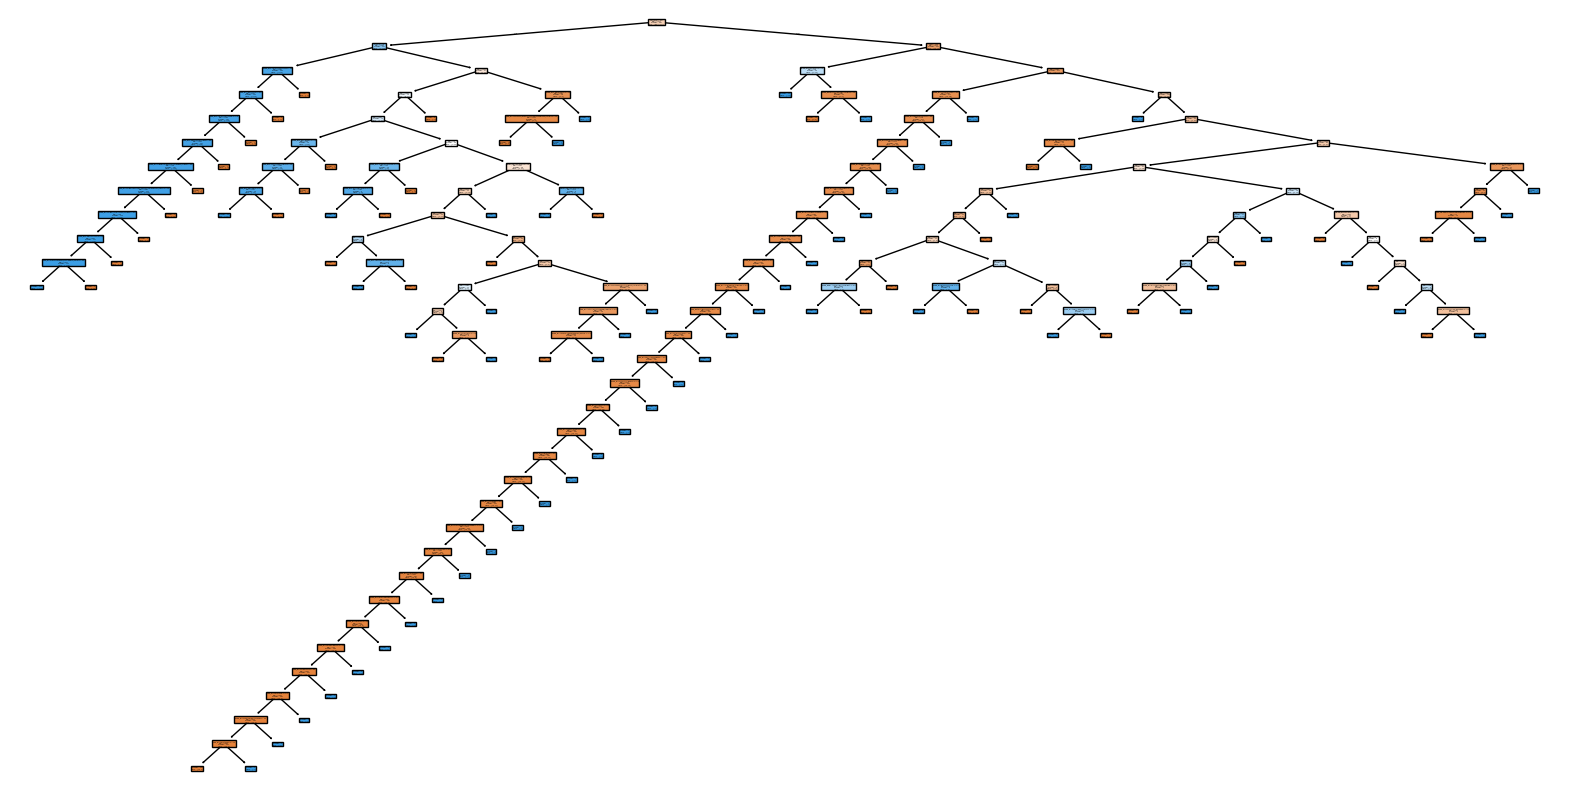

Accuracy: 0.8576779026217228


In [18]:
dataset = pd.read_csv("titanic.csv")
#print(dataset.head)

# remove values nulls
clean_data = dataset.dropna()

# transform categorical in numeric
clean_data = pd.get_dummies(clean_data, drop_first = True)

# x -> input / y -> output
x = clean_data.drop(columns=["Survived"])
y = clean_data["Survived"]


# 70 training / 30 validation
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=6)

# model Decision Tree
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

# plot tree
plt.figure(figsize=(20,10))
plot_tree(model, filled=True, feature_names=X_train.columns)
plt.show()

# evaluate accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

 2- Considere ainda uma árvore de decisão para classificar se um indivíduo sobreviveu ou não com
 base no dataset “titanic.csv”. Qual o resultado médio de acurácia utilizando a estratégia de
 validação cruzada 10-fold? Discuta os resultados

In [32]:
# model decision tree
model = DecisionTreeClassifier()

# crusades validation
crusades = cross_val_score(model, x, y, cv = 10)

# results
print("Acurácia média:", crusades.mean())

Acurácia média: 0.8388278855975484


**Pode-se observar que a acurácia do modelo de arvore sem validação crusada acabou sendo maior, podem existir várias hipoteses para esse ocorrido, talvez tenha acontecido um overfitting onde sua acurácia está artificialmente alta, talvez o modelo de distribuição de teste e treino favoreceu o modelo, entre outras hipoteses...**

 3- Ainda considerando o dataset “titanic.csv”, construa um modelo utilizando k-NN para prever se
 uma pessoa sobreviveu ou não. Considere diferentes valores de k vizinhos: k={2,3,4,5,6,7}. Houve
 variação significativa nos diferentes modelos testados? Algum deles foi melhor do que a estratégia
 baseada em árvore de decisão?

In [36]:
# K values
k_values = [2, 3, 4, 5, 6, 7]

# model KNN
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print("k =", k, "Acurácia:", accuracy)


k = 2 Acurácia: 0.6741573033707865
k = 3 Acurácia: 0.6966292134831461
k = 4 Acurácia: 0.6966292134831461
k = 5 Acurácia: 0.6816479400749064
k = 6 Acurácia: 0.6704119850187266
k = 7 Acurácia: 0.6779026217228464


***Pode-se notar que com valores de k entre 3 e 5 o modelo apresenta um melhor desempenho, porém se mostra bem abaixo das arvores de decisão.***